# Diabetes Prediction Using Machine Learning



## 1. Import Required Libraries



In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)


## 2. Define Paths and Load Cleaned Dataset




In [4]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_RELATIVE_PATH = Path("data") / "processed" / "diabetes_cleaned.csv"
FIGURES_RELATIVE_DIR = Path("outputs") / "figures" 
TABLES_RELATIVE_DIR = Path("outputs") / "tables" 

DATASET_PATH = PROJECT_ROOT / DATASET_RELATIVE_PATH
FIGURES_DIR = PROJECT_ROOT / FIGURES_RELATIVE_DIR
TABLES_DIR = PROJECT_ROOT / TABLES_RELATIVE_DIR

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Cleaned dataset not found: {DATASET_RELATIVE_PATH}")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATASET_PATH)
print("Cleaned dataset loaded successfully.")
print(f"Dataset path: {DATASET_RELATIVE_PATH}")


Cleaned dataset loaded successfully.
Dataset path: data\processed\diabetes_cleaned.csv


## 3. Verify Dataset Columns

The expected column check prevents accidental analysis of the wrong dataset file.


In [5]:
EXPECTED_COLUMNS = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

missing_columns = [column for column in EXPECTED_COLUMNS if column not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

FEATURE_COLUMNS = [column for column in EXPECTED_COLUMNS if column != "Outcome"]
print("All expected columns are present.")


All expected columns are present.


## 4. Dataset Overview



In [6]:
overview = pd.DataFrame({
    "item": ["dataset_path", "rows", "columns", "missing_values", "duplicate_rows", "input_features", "target_variable"],
    "value": [
        str(DATASET_PATH.relative_to(PROJECT_ROOT)),
        df.shape[0],
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        len(FEATURE_COLUMNS),
        "Outcome",
    ],
})

print("Dataset shape:", df.shape)
display(df.head())
display(df.tail())
display(df.dtypes.reset_index().rename(columns={"index": "column_name", 0: "data_type"}))
display(overview)


Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101.0,76.0,48.0,180.0,32.9,0.171,63,0
764,2,122.0,70.0,27.0,125.0,36.8,0.340,27,0
765,5,121.0,72.0,23.0,112.0,26.2,0.245,30,0
766,1,126.0,60.0,29.0,125.0,30.1,0.349,47,1
767,1,93.0,70.0,31.0,125.0,30.4,0.315,23,0


,column_name,data_type
0,Pregnancies,int64
1,Glucose,float64
2,BloodPressure,float64
3,SkinThickness,float64
4,Insulin,float64
5,BMI,float64
6,DiabetesPedigreeFunction,float64
7,Age,int64
8,Outcome,int64


,item,value
0,dataset_path,data\processed\diabetes_cleaned.csv
1,rows,768
2,columns,9
3,missing_values,0
4,duplicate_rows,0
5,input_features,8
6,target_variable,Outcome


## 5. Save Basic Numerical Summaries



In [8]:
descriptive_stats = df.describe().T.reset_index().rename(columns={"index": "column_name"})
class_distribution = df["Outcome"].value_counts().sort_index().rename_axis("Outcome").reset_index(name="count")
class_distribution.insert(0, "analysis_stage", "EDA")
class_distribution["percentage"] = (class_distribution["count"] / len(df) * 100).round(2)

overview.to_csv(TABLES_DIR / "dataset_overview.csv", index=False)
descriptive_stats.to_csv(TABLES_DIR / "descriptive_statistics.csv", index=False)
class_distribution.to_csv(TABLES_DIR / "class_distribution.csv", index=False)

display(descriptive_stats)
display(class_distribution)


,column_name,count,mean,std,min,25%,50%,75%,max
0,Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
1,Glucose,768.0,121.656250,30.438286,44.000,99.75000,117.0000,140.25000,199.00
2,BloodPressure,768.0,72.386719,12.096642,24.000,64.00000,72.0000,80.00000,122.00
3,SkinThickness,768.0,29.108073,8.791221,7.000,25.00000,29.0000,32.00000,99.00
4,Insulin,768.0,140.671875,86.383060,14.000,121.50000,125.0000,127.25000,846.00
5,BMI,768.0,32.455208,6.875177,18.200,27.50000,32.3000,36.60000,67.10
6,DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
7,Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
8,Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


,analysis_stage,Outcome,count,percentage
0,EDA,0,500,65.1
1,EDA,1,268,34.9


## 6. Class Distribution Countplot

This countplot shows how many records belong to each target class.


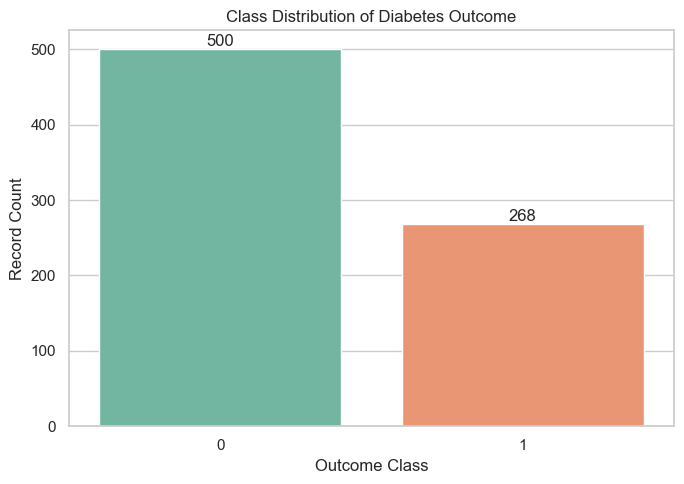

In [9]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="Outcome", hue="Outcome", palette="Set2", legend=False)
ax.set_title("Class Distribution of Diabetes Outcome")
ax.set_xlabel("Outcome Class")
ax.set_ylabel("Record Count")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution_countplot.png", dpi=150)
plt.show()
plt.close()


### Class Distribution Interpretation

The graph shows that class `0` has `500` records (`65.1%`) and class `1` has `268` records (`34.9%`). Class `0` is larger than class `1`, so the dataset is moderately imbalanced. For model building later, this means accuracy alone may not be enough; precision, recall, F1-score, and confusion matrix should also be checked.


## 7. Histograms for All Input Features

Histograms show the distribution of each input feature. They help identify skewness, concentration of values, and possible extreme values.


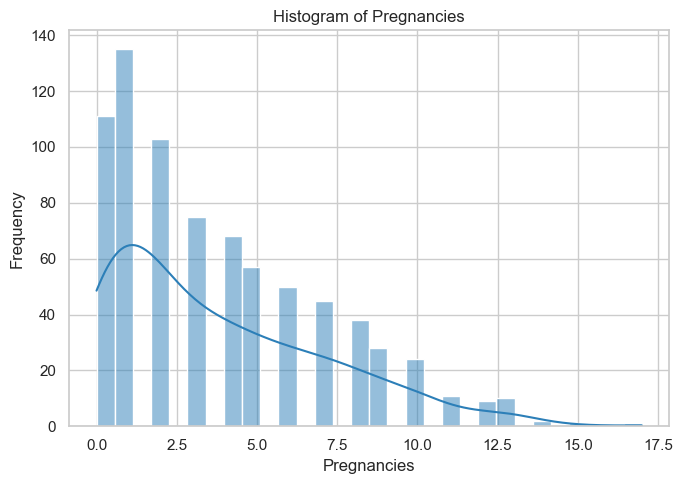

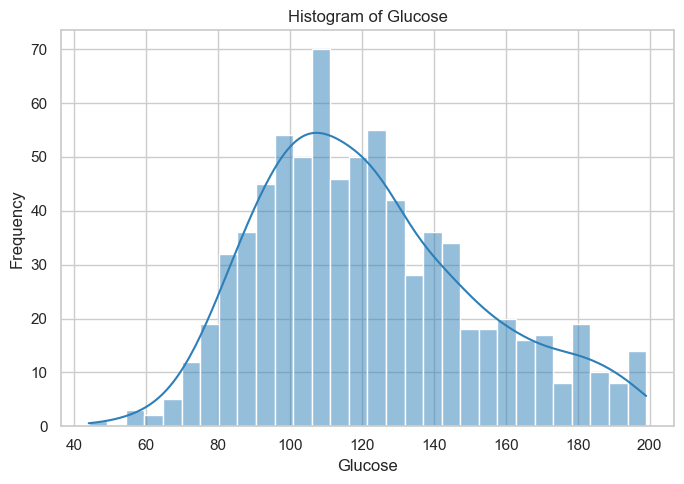

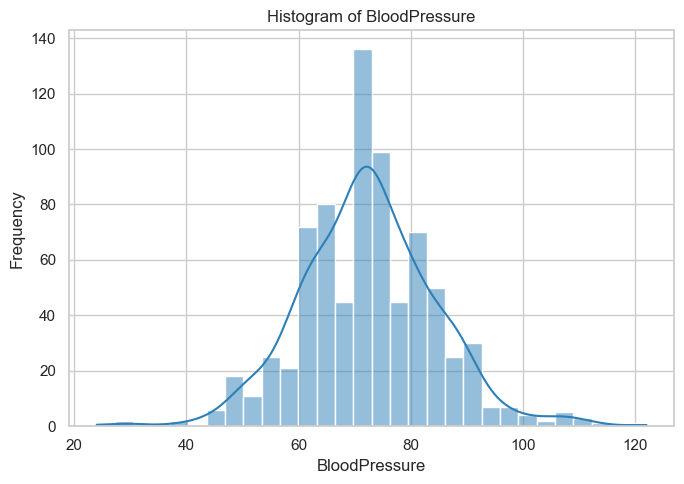

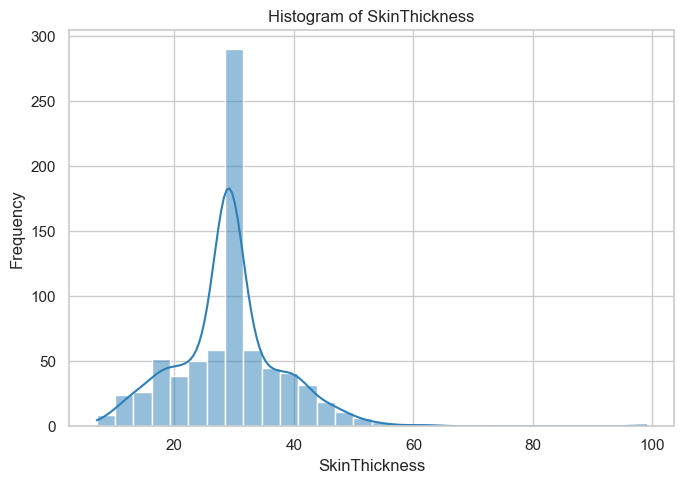

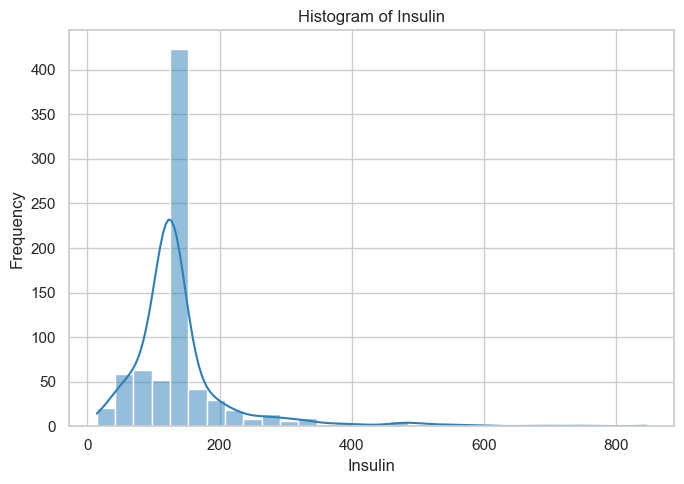

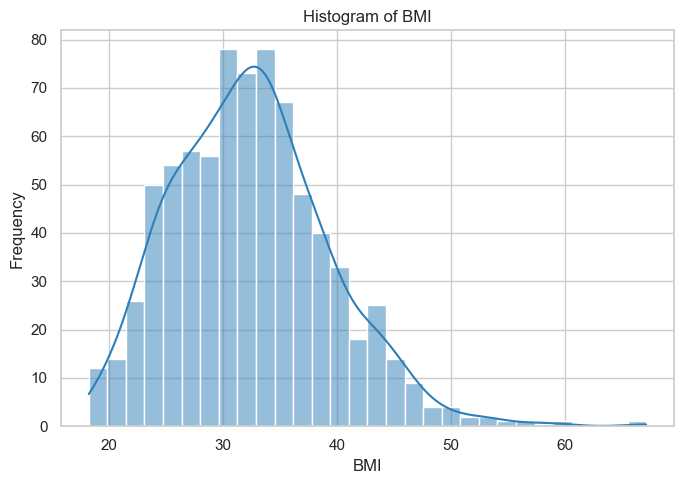

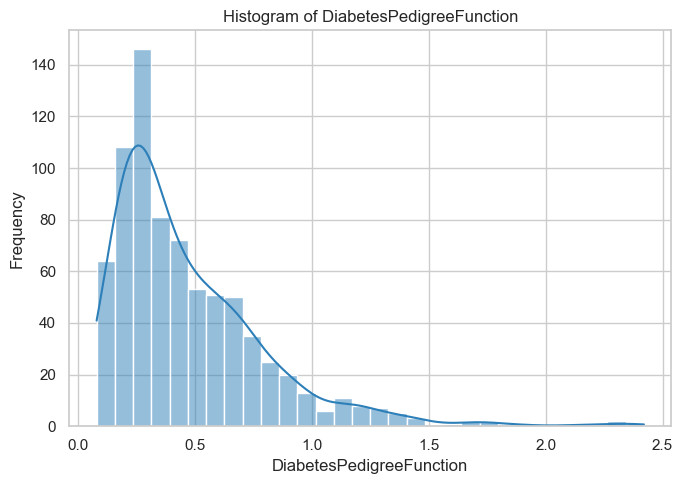

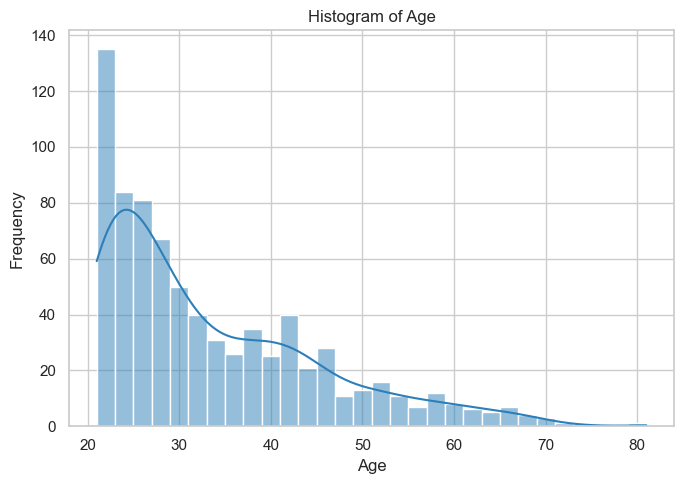

In [10]:
for column in FEATURE_COLUMNS:
    plt.figure(figsize=(7, 5))
    sns.histplot(data=df, x=column, kde=True, bins=30, color="#2C7FB8")
    plt.title(f"Histogram of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"histogram_{column.lower()}.png", dpi=150)
    plt.show()
    plt.close()


### Histogram Interpretation

The histograms show how patient measurements are spread across the dataset.

- `Pregnancies`: mean `3.85`, median `3.00`; the distribution appears right-skewed.
- `Glucose`: mean `121.66`, median `117.00`; the distribution appears right-skewed.
- `BloodPressure`: mean `72.39`, median `72.00`; the distribution appears right-skewed.
- `SkinThickness`: mean `29.11`, median `29.00`; the distribution appears right-skewed.
- `Insulin`: mean `140.67`, median `125.00`; the distribution appears right-skewed.
- `BMI`: mean `32.46`, median `32.30`; the distribution appears right-skewed.
- `DiabetesPedigreeFunction`: mean `0.47`, median `0.37`; the distribution appears right-skewed.
- `Age`: mean `33.24`, median `29.00`; the distribution appears right-skewed.

Several medical features are not perfectly normal in shape. This can affect later model building because algorithms may respond differently to skewed features and extreme values.


## 8. Boxplots for All Input Features

Boxplots show the median, spread, and possible outliers for each input feature. Outliers are only identified and are not removed.


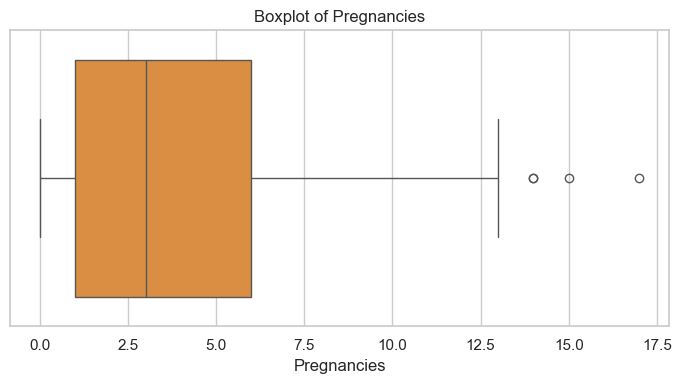

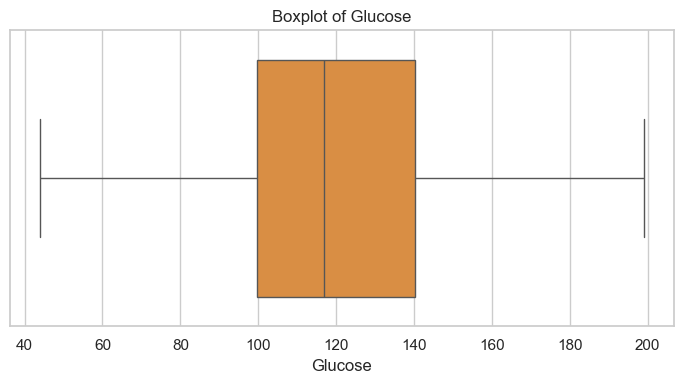

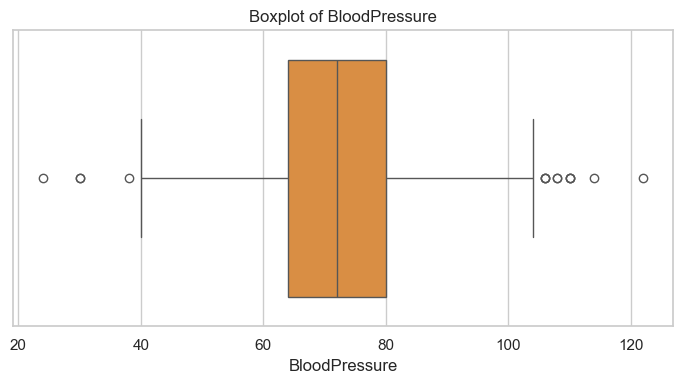

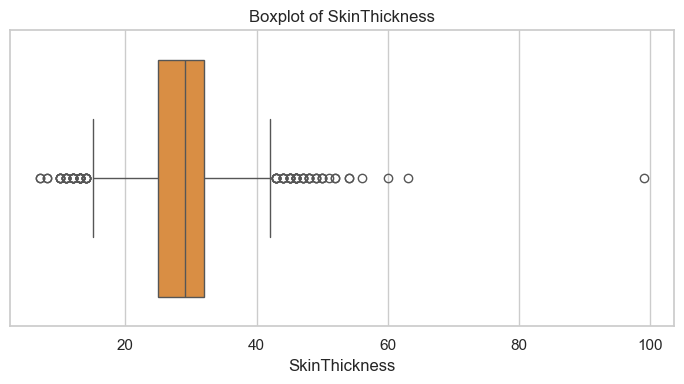

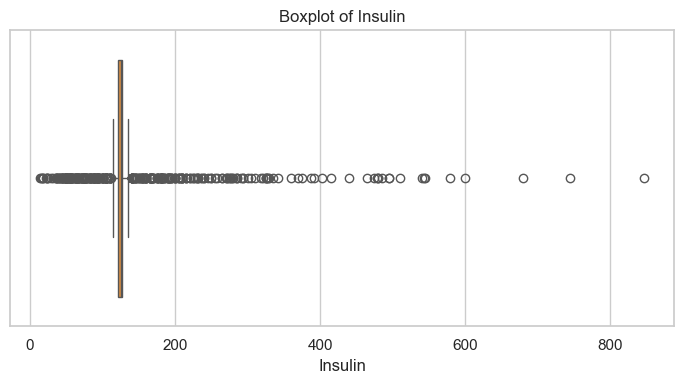

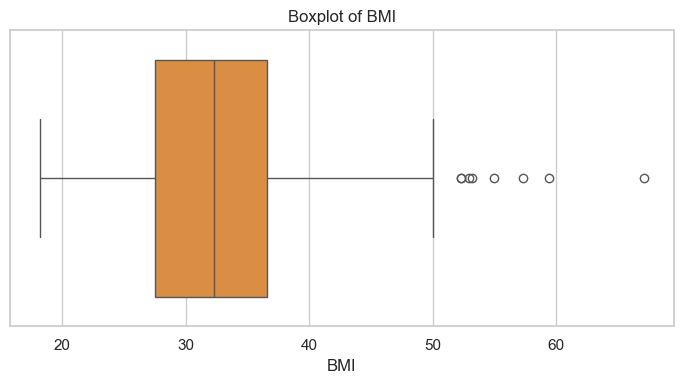

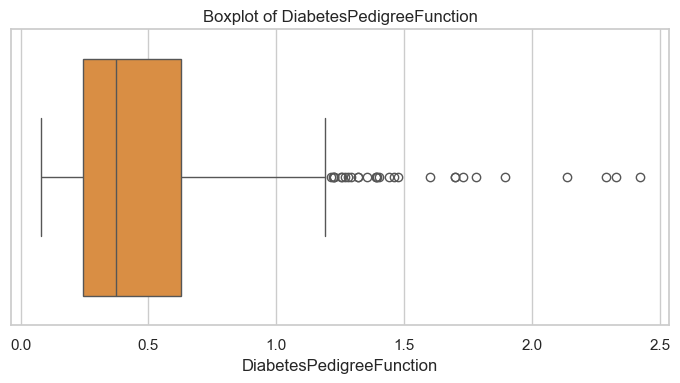

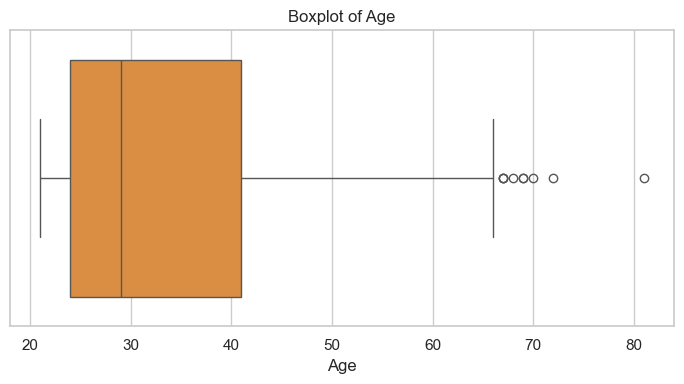

In [11]:
for column in FEATURE_COLUMNS:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=column, color="#F28E2B")
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"boxplot_{column.lower()}.png", dpi=150)
    plt.show()
    plt.close()


### Boxplot Interpretation

The boxplots show that some features contain values far from the central range. These values may be true medical variation or possible unusual records. They are not removed in Week 7.

- `Insulin`: `346` IQR outliers using bounds `112.875` to `135.875`.
- `SkinThickness`: `87` IQR outliers using bounds `14.5` to `42.5`.
- `DiabetesPedigreeFunction`: `29` IQR outliers using bounds `-0.33` to `1.2`.
- `BloodPressure`: `14` IQR outliers using bounds `40.0` to `104.0`.
- `Age`: `9` IQR outliers using bounds `-1.5` to `66.5`.
- `BMI`: `8` IQR outliers using bounds `13.85` to `50.25`.
- `Pregnancies`: `4` IQR outliers using bounds `-6.5` to `13.5`.
- `Glucose`: `0` IQR outliers using bounds `39.0` to `201.0`.

For model building later, outliers may influence distance-based or linear models, so scaling and robust evaluation will be important.


## 9. Outlier Summary Using IQR Method

The IQR method uses the first quartile, third quartile, and interquartile range to detect possible outliers. This table documents outliers but does not remove them.


In [12]:
outlier_rows = []
for column in FEATURE_COLUMNS:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = int(((df[column] < lower_bound) | (df[column] > upper_bound)).sum())
    outlier_rows.append({
        "feature_name": column,
        "q1": round(q1, 4),
        "q3": round(q3, 4),
        "iqr": round(iqr, 4),
        "lower_bound": round(lower_bound, 4),
        "upper_bound": round(upper_bound, 4),
        "outlier_count": outlier_count,
        "outlier_percentage": round(outlier_count / len(df) * 100, 2),
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_count", ascending=False).reset_index(drop=True)
outlier_summary.to_csv(TABLES_DIR / "outlier_summary.csv", index=False)
display(outlier_summary)


,feature_name,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percentage
0,Insulin,121.5000,127.2500,5.7500,112.875,135.875,346,45.05
1,SkinThickness,25.0000,32.0000,7.0000,14.500,42.500,87,11.33
2,DiabetesPedigreeFunction,0.2438,0.6262,0.3825,-0.330,1.200,29,3.78
3,BloodPressure,64.0000,80.0000,16.0000,40.000,104.000,14,1.82
4,Age,24.0000,41.0000,17.0000,-1.500,66.500,9,1.17
5,BMI,27.5000,36.6000,9.1000,13.850,50.250,8,1.04
6,Pregnancies,1.0000,6.0000,5.0000,-6.500,13.500,4,0.52
7,Glucose,99.7500,140.2500,40.5000,39.000,201.000,0,0.00


### Outlier Summary Interpretation

The IQR table gives a numerical count of possible outliers for each feature. These records should be studied carefully in later stages, but removing them automatically may remove useful medical information.


## 10. Correlation Heatmap

The heatmap shows linear relationships between numeric columns. Values close to `1` are strong positive relationships, values close to `-1` are strong negative relationships, and values near `0` are weak linear relationships.


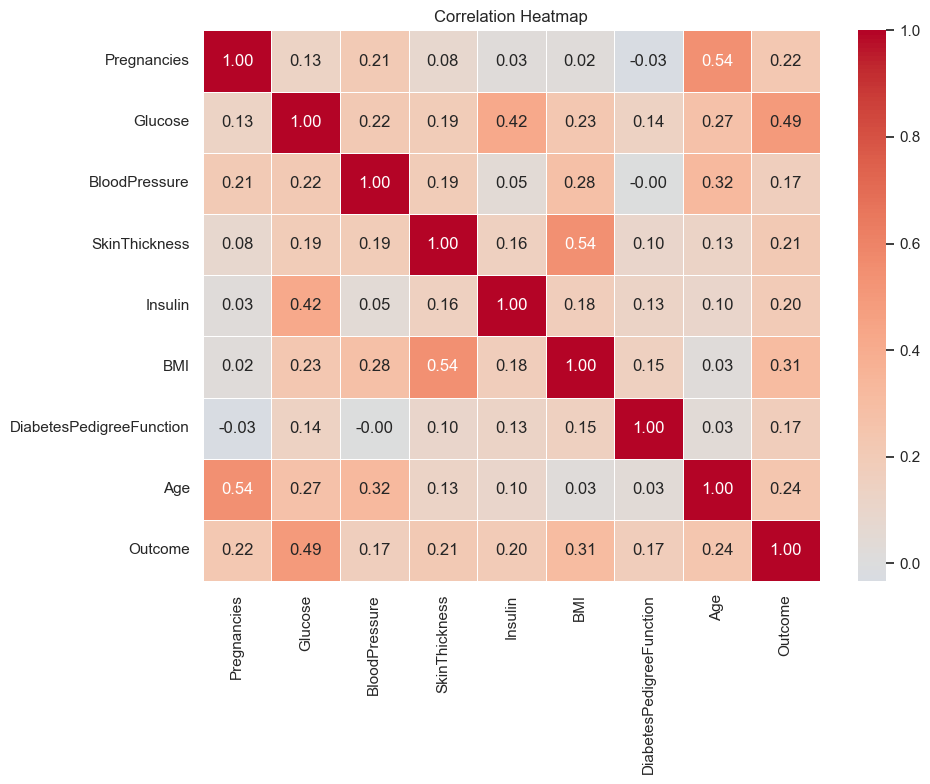

,feature_1,feature_2,correlation,absolute_correlation
0,Pregnancies,Age,0.544341,0.544341
1,SkinThickness,BMI,0.543205,0.543205
2,Glucose,Outcome,0.492782,0.492782
3,Glucose,Insulin,0.419451,0.419451
4,BloodPressure,Age,0.324915,0.324915
5,BMI,Outcome,0.312038,0.312038
6,BloodPressure,BMI,0.281257,0.281257
7,Glucose,Age,0.266909,0.266909
8,Age,Outcome,0.238356,0.238356
9,Glucose,BMI,0.231049,0.231049


,feature_name,correlation_with_outcome
0,Glucose,0.492782
1,BMI,0.312038
2,Age,0.238356
3,Pregnancies,0.221898
4,SkinThickness,0.214873
5,Insulin,0.203790
6,DiabetesPedigreeFunction,0.173844
7,BloodPressure,0.165723


In [13]:
correlation_matrix = df.corr(numeric_only=True)
correlation_matrix.to_csv(TABLES_DIR / "correlation_matrix.csv")

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=150)
plt.show()
plt.close()

correlation_long = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)).stack().reset_index()
correlation_long.columns = ["feature_1", "feature_2", "correlation"]
correlation_long["absolute_correlation"] = correlation_long["correlation"].abs()
strongest_correlations = correlation_long.sort_values("absolute_correlation", ascending=False).head(10).reset_index(drop=True)
outcome_correlations = correlation_matrix["Outcome"].drop("Outcome").sort_values(key=lambda series: series.abs(), ascending=False).reset_index()
outcome_correlations.columns = ["feature_name", "correlation_with_outcome"]
strongest_correlations.to_csv(TABLES_DIR / "strongest_correlations.csv", index=False)
outcome_correlations.to_csv(TABLES_DIR / "outcome_correlations.csv", index=False)
display(strongest_correlations)
display(outcome_correlations)


### Correlation Heatmap Interpretation

The strongest overall feature relationships are `Pregnancies` with `Age` (`0.544`), `SkinThickness` with `BMI` (`0.543`), and `Glucose` with `Outcome` (`0.493`).

For the target variable, the strongest correlations are with `Glucose` (`0.493`), `BMI` (`0.312`), and `Age` (`0.238`). These features may be important for later model building, but correlation alone does not prove causation.


## 11. Pairplot for Selected Features

A pairplot shows pairwise relationships between selected important features. A subset is used for readability.


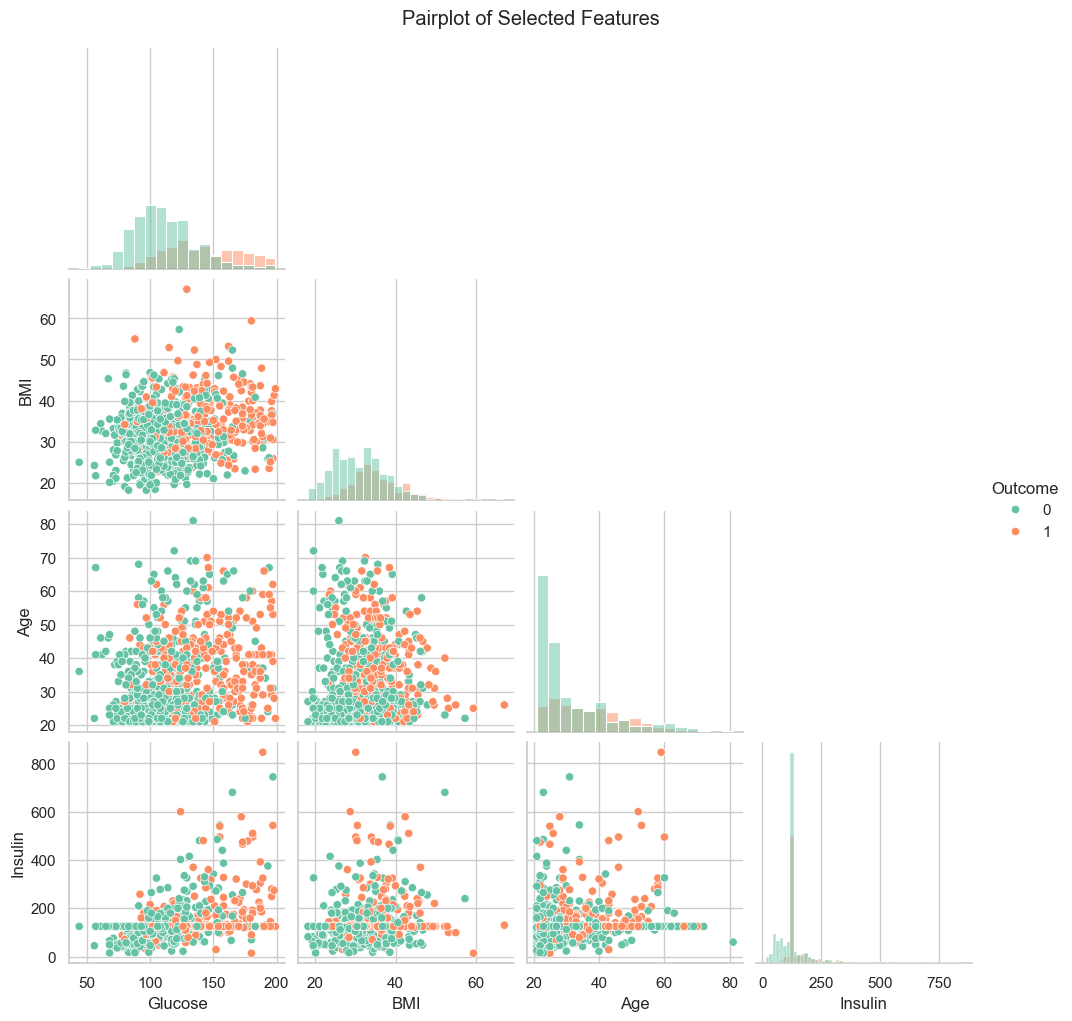

In [14]:
PAIRPLOT_COLUMNS = ["Glucose", "BMI", "Age", "Insulin", "Outcome"]
pair_grid = sns.pairplot(df[PAIRPLOT_COLUMNS], hue="Outcome", diag_kind="hist", corner=True, palette="Set2")
pair_grid.fig.suptitle("Pairplot of Selected Features", y=1.02)
pair_grid.savefig(FIGURES_DIR / "pairplot_selected_features.png", dpi=150)
plt.show()
plt.close("all")


### Pairplot Interpretation

The pairplot compares selected features by target class. It helps show whether diabetic and non-diabetic records separate clearly in two-feature views. Some class separation is visible around glucose and BMI, but the classes still overlap, so later models will need to combine multiple features rather than depend on one feature alone.


## 12. Scatter Plot: Glucose vs BMI

This scatter plot checks whether glucose and BMI together show visible separation between target classes.


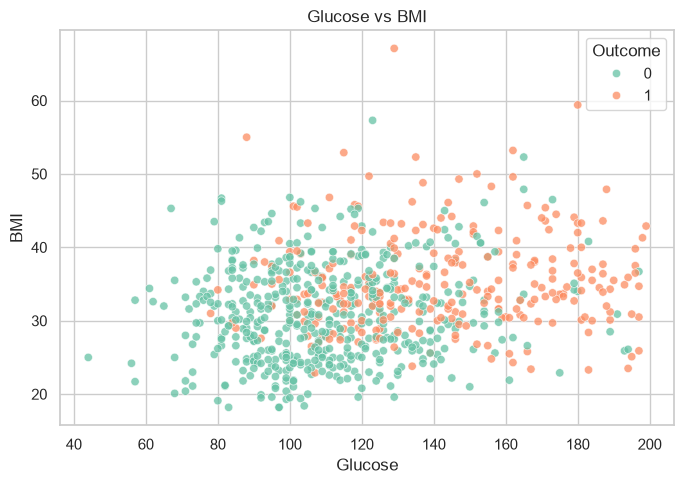

In [12]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Glucose", y="BMI", hue="Outcome", palette="Set2", alpha=0.75)
plt.title("Glucose vs BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "scatter_glucose_vs_bmi.png", dpi=150)
plt.show()
plt.close()


### Glucose vs BMI Interpretation

The graph shows patient records plotted by glucose and BMI. Higher glucose values appear more common among class `1` records, while BMI also contributes some separation. However, there is overlap between the classes, so both features should be combined with other inputs later.


## 13. Scatter Plot: Age vs Glucose

This scatter plot checks how age and glucose vary across target classes.


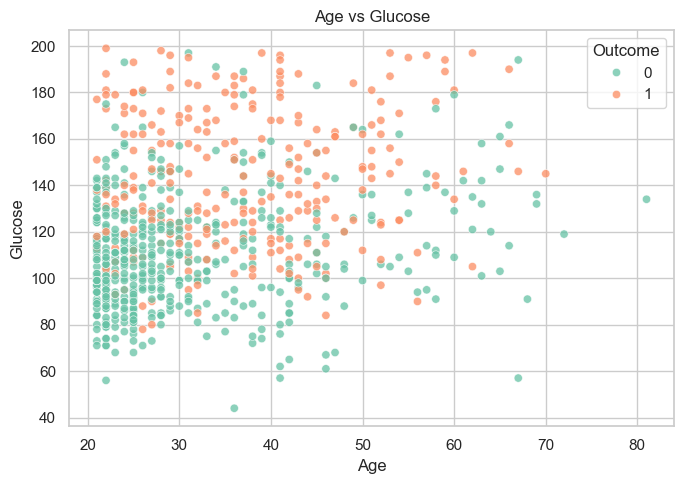

In [16]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Age", y="Glucose", hue="Outcome", palette="Set2", alpha=0.75)
plt.title("Age vs Glucose")
plt.xlabel("Age")
plt.ylabel("Glucose")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "scatter_age_vs_glucose.png", dpi=150)
plt.show()
plt.close()


### Age vs Glucose Interpretation

The graph shows that higher glucose values are often associated with class `1`, and older patients also appear more frequently in class `1`. The classes still overlap, so age and glucose are useful signals but not perfect separators.


## 14. Scatter Plot: BMI vs Insulin

This scatter plot checks the relationship between BMI and insulin.


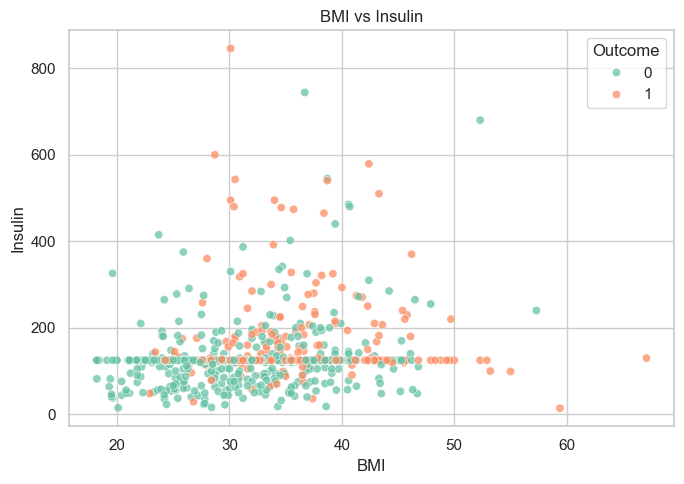

In [17]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="BMI", y="Insulin", hue="Outcome", palette="Set2", alpha=0.75)
plt.title("BMI vs Insulin")
plt.xlabel("BMI")
plt.ylabel("Insulin")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "scatter_bmi_vs_insulin.png", dpi=150)
plt.show()
plt.close()


### BMI vs Insulin Interpretation

The graph shows a wide spread of insulin values for different BMI levels. Some high insulin values appear as possible outliers. This suggests insulin may need careful handling and evaluation in later modelling, but no outliers are removed.


## 15. Key Insights from EDA

- The cleaned dataset has `768` rows and `9` columns with no missing values.
- The target distribution is moderately imbalanced: class `0` has `500` records and class `1` has `268` records.
- `Glucose`, `BMI`, and `Age` have the strongest correlations with `Outcome`.
- The strongest feature-to-feature relationship is `Pregnancies` with `Age`.
- IQR outliers are highest in `Insulin` (`346`), `SkinThickness` (`87`), and `DiabetesPedigreeFunction` (`29`).
- Glucose and BMI show useful visual patterns for diabetes outcome, but the classes overlap.
- No feature engineering, outlier removal, dataset modification, or model training was performed.
